# CS 3110/5110: Data Privacy

## In-Class Exercise, week of 11/9/2026


In [4]:
# Load the data and libraries
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt


def laplace_mech(v, sensitivity, epsilon):
    return v + np.random.laplace(loc=0, scale=sensitivity / epsilon)


def gaussian_mech(v, sensitivity, epsilon, delta):
    return v + np.random.normal(
        loc=0, scale=sensitivity * np.sqrt(2 * np.log(1.25 / delta)) / epsilon
    )


def gaussian_mech_vec(vec, sensitivity, epsilon, delta):
    return [
        v
        + np.random.normal(
            loc=0,
            scale=sensitivity * np.sqrt(2 * np.log(1.25 / delta)) / epsilon,
        )
        for v in vec
    ]


def pct_error(orig, priv):
    return np.abs(orig - priv) / orig * 100.0


adult = pd.read_csv(
    "https://github.com/jnear/cs3110-data-privacy/raw/main/homework/adult_with_pii.csv"
)

## Question 1

Implement an _encoding function_ for randomized response to a "yes/no" question.

Reference [Chapter 13](https://uvm-plaid.github.io/programming-dp/notebooks/ch13.html#randomized-response).


In [5]:
def encode_rand_resp_yes_no(true_response):
    # 1. Flip a coin
    first_coin = np.random.randint(0, 2)
    # 2. If heads, answer truthfully
    #    Else, flip another coint and answer what it says
    if first_coin == 0:
        return true_response
    else:
        return np.random.randint(0, 2) == 0


for _ in range(5):
    print("Randomized response:", encode_rand_resp_yes_no(True))

Randomized response: True
Randomized response: True
Randomized response: True
Randomized response: True
Randomized response: False


In [6]:
# TEST CASE
assert np.sum([encode_rand_resp_yes_no(True) for _ in range(100)]) > 60
assert np.sum([encode_rand_resp_yes_no(True) for _ in range(100)]) < 90

## Question 2

Implement a _decoding function_ for randomized response to a "yes/no" question.


In [23]:
def decode_rand_resp_yes_no(responses):
    # This is where we correct for the bias introduced by having half of the
    # encoded resposes be random.
    fake_responses = len(responses) / 2
    # Total number of recorded yesses
    num_yesses = np.sum(responses)
    # number of expected "real" yesses, is the total number of yesses * 2
    # minus the number of fake responses
    true_yesses = num_yesses * 2 - fake_responses
    return true_yesses


# Example: 1000 "yesses" and 500 "nos"
true_responses = [True for _ in range(1000)] + [False for _ in range(500)]
print('Number of "True" yesses:', np.sum(true_responses))

# Randomized responses
# Each response satisfies 1.09-differential privacy
rand_responses = [encode_rand_resp_yes_no(r) for r in true_responses]

# Decode the responses by subtracting "fake" yesses
print(
    "Decoded randomized response yesses:",
    decode_rand_resp_yes_no(rand_responses),
)

Number of "True" yesses: 1000
Decoded randomized response yesses: 1028.0


In [24]:
# TEST CASE
true_responses = [True for _ in range(1000)] + [False for _ in range(500)]

# Randomized responses
# Each response satisfies 1.09-differential privacy
rand_responses = [encode_rand_resp_yes_no(r) for r in true_responses]

# Decode the responses by subtracting "fake" yesses
assert decode_rand_resp_yes_no(rand_responses) < 1100
assert decode_rand_resp_yes_no(rand_responses) > 900

## Question 3

Use the definition of randomized response above to answer the question:

_How many individuals in the `adult` dataset have `Occupation` = `Sales`?_


In [36]:
# take a single occupation from the adult dataset, and return a single response
def encode_response_sales(response):
    return encode_rand_resp_yes_no(response == "Sales")


def decode_responses_sales(responses):
    return decode_rand_resp_yes_no(responses)


responses = [encode_response_sales(r) for r in adult["Occupation"]]
decode_responses_sales(responses)

np.float64(3521.5)

In [27]:
# How accurate is the answer above?
true_sales = np.sum(adult["Occupation"] == "Sales")
print("True number of salespeople:", true_sales)

True number of salespeople: 3650


## Question 4

Implement the _encode_ and _perturb_ steps for Optimized Unary Hashing.


In [ ]:
domain = adult["Occupation"].dropna().unique()
domain

# Unary Hashing is used for histograms


def encode(response):
    # one-hot encode the response
    return [1 if d == response else 0 for d in domain]


encode("Sales")


# defines how we will randomly flip bits
def perturb(encoded_response):
    def perturb_bit(bit):
        p = 0.75
        q = 0.25

        sample = np.random.rand()

        if bit == 1:
            if sample <= p:
                return 1
            else:
                return 0
        else:
            if sample <= q:
                return 1
            else:
                return 0

    return [perturb_bit(b) for b in encoded_response]


perturb(encode("Sales"))

[1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]

In [55]:
# As in randomized response, flipping of bits causes issues in the answers
# This is the perturbed answer (without decoding)
counts = np.sum([perturb(encode(r)) for r in adult["Occupation"]], axis=0)
list(zip(domain, counts))

[('Adm-clerical', np.int64(10063)),
 ('Exec-managerial', np.int64(10057)),
 ('Handlers-cleaners', np.int64(8829)),
 ('Prof-specialty', np.int64(10280)),
 ('Other-service', np.int64(9904)),
 ('Sales', np.int64(10008)),
 ('Craft-repair', np.int64(10174)),
 ('Transport-moving', np.int64(9099)),
 ('Farming-fishing', np.int64(8716)),
 ('Machine-op-inspct', np.int64(9293)),
 ('Tech-support', np.int64(8522)),
 ('Protective-serv', np.int64(8453)),
 ('Armed-Forces', np.int64(8204)),
 ('Priv-house-serv', np.int64(8318))]

In [50]:
# This is the real answer
counts = np.sum([encode(r) for r in adult["Occupation"]], axis=0)
list(zip(domain, counts))

[('Adm-clerical', np.int64(3770)),
 ('Exec-managerial', np.int64(4066)),
 ('Handlers-cleaners', np.int64(1370)),
 ('Prof-specialty', np.int64(4140)),
 ('Other-service', np.int64(3295)),
 ('Sales', np.int64(3650)),
 ('Craft-repair', np.int64(4099)),
 ('Transport-moving', np.int64(1597)),
 ('Farming-fishing', np.int64(994)),
 ('Machine-op-inspct', np.int64(2002)),
 ('Tech-support', np.int64(928)),
 ('Protective-serv', np.int64(649)),
 ('Armed-Forces', np.int64(9)),
 ('Priv-house-serv', np.int64(149))]

## Question 5

Implement the _aggregate_ step for Optimized Unary Hashing.


In [ ]:
# This function removes the statistical bias from responses by adjusting for p and q
def aggregate(responses):
    p = 0.75
    q = 0.25
    sums = np.sum(responses, axis=0)
    n = len(responses)
    return [(v - n * q) / (p - q) for v in sums]


responses = [perturb(encode(r)) for r in adult["Occupation"]]
counts = aggregate(responses)
list(zip(domain, counts))

[('Adm-clerical', np.float64(3861.5)),
 ('Exec-managerial', np.float64(4023.5)),
 ('Handlers-cleaners', np.float64(1175.5)),
 ('Prof-specialty', np.float64(4191.5)),
 ('Other-service', np.float64(3107.5)),
 ('Sales', np.float64(3671.5)),
 ('Craft-repair', np.float64(4175.5)),
 ('Transport-moving', np.float64(1549.5)),
 ('Farming-fishing', np.float64(777.5)),
 ('Machine-op-inspct', np.float64(2027.5)),
 ('Tech-support', np.float64(987.5)),
 ('Protective-serv', np.float64(483.5)),
 ('Armed-Forces', np.float64(21.5)),
 ('Priv-house-serv', np.float64(157.5))]

We can calculate the epsilon from the p and q using the following formula:
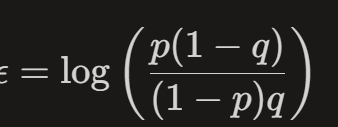
